# Bab 6 — Statistical Machine Learning

### Identitas Mahasiswa

| Detail | Identitas |
|---|---|
| Nama | Hadi Nugroho |
| NIM | 101032330235 |

**Tujuan pembelajaran.** menerapkan K-nearest neighbors beserta pilihan jarak, one-hot encoding, standardisasi, dan K; membangun serta membaca decision tree; mengukur impurity dan mengendalikan overfitting; memahami bagging, random forest, out-of-bag error, dan variable importance; memahami algoritme boosting dan menyetel XGBoost dengan regularisasi serta cross-validation.

**Ringkasan bab.** Metode statistical machine learning bersifat *data-driven*: tidak memaksakan struktur linear seperti regresi, melainkan membiarkan data menentukan bentuk hubungan. KNN memprediksi dari tetangga terdekat sehingga sangat bergantung pada skala dan definisi jarak. Decision tree membagi ruang prediktor secara rekursif menjadi aturan if-then yang mudah dibaca, tetapi satu tree tidak stabil. Ensemble mengatasi hal itu: bagging dan random forest merata-ratakan banyak tree dari sampel bootstrap, sedangkan boosting menambahkan model secara berurutan untuk memperbaiki kesalahan sebelumnya. Model fleksibel mudah overfit, sehingga hyperparameter harus dipilih dengan data validasi atau cross-validation.

Notebook belajar dan reproduksi edisi kedua (Bruce, Bruce, Gedeck, 2020). Penjelasan ditulis ulang dengan bantuan AI; kode diadaptasi dari repository resmi berlisensi GPL-3.0. Bagian tambahan diberi label. Nomor halaman merujuk halaman cetak; nomor PDF = cetak + 18.

## Setup dan dataset

| File | Unit observasi dan kolom | Makna |
|---|---|---|
| `loan200.csv` | 201 baris; `outcome`, `payment_inc_ratio`, `dti` | Baris indeks 0 berlabel `target` adalah **pinjaman baru** yang akan diprediksi; 200 baris lain (96 default, 104 paid off) adalah data latih contoh KNN kecil |
| `loan3000.csv` | 3.000 pinjaman; 1.445 default, 1.555 paid off | Contoh dua prediktor (`borrower_score`, `payment_inc_ratio`) untuk tree, random forest, dan XGBoost |
| `loan_data.csv.gz` | 45.342 pinjaman seimbang (50% default) | Contoh standardisasi, KNN feature engine, variable importance, dan regularisasi XGBoost |
| `house_sales.csv` | 22.687 transaksi rumah King County (Bab 4) | Dipakai ulang hanya pada demonstrasi tambahan regression tree |
| Prediktor kredit | `payment_inc_ratio`, `dti`, `revol_bal` (USD), `revol_util` (%), `open_acc`, `delinq_2yrs_zero`, `pub_rec_zero`, `loan_amnt` (USD), `annual_inc` (USD), `term`, `grade`, `emp_length`, `purpose`, `purpose_`, `home_`, `emp_len_`, `borrower_score` | `delinq_2yrs_zero`/`pub_rec_zero` bernilai 1 jika tidak ada tunggakan 2 tahun/catatan publik; `grade` numerik dari data buku; `purpose` adalah versi rinci dari `purpose_` |

Kelas positif untuk model biner adalah **default** (y=1), sama dengan Bab 5. Kolom `status` tidak dipakai sebagai prediktor karena menentukan `outcome`. `borrower_score` dibuat dari outcome data yang sama (dibuktikan pada bagian *KNN as a Feature Engine*), sehingga hasil yang memakainya diberi catatan leakage. Satuan `payment_inc_ratio` dan `dti` tidak dicantumkan eksplisit di CSV, jadi label grafik memakai skala dataset.

Sumber file: [repository pendamping edisi kedua](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa/data). Commit sumber dan checksum dicatat di `data/manifest.json`.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # saran repository buku bila XGBoost crash di macOS
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import seaborn as sns
from IPython.display import display
from importlib.metadata import version

ROOT = Path.cwd()
if not (ROOT / "data/manifest.json").exists():
    raise FileNotFoundError("Buka folder proyek sebagai workspace dan jalankan notebook dari root proyek.")
DATA = ROOT / "data"
SEED = 1
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 25)
print("Python:", sys.version.split()[0])
print("Data:", DATA.relative_to(ROOT))
print("Versi:", {lib: version(lib) for lib in ["numpy", "pandas", "scikit-learn", "xgboost"]})

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict)
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

def load_loans(name):
    df = pd.read_csv(DATA / name)
    df = df.drop(columns=[c for c in ["Unnamed: 0", "status"] if c in df.columns])
    df["y"] = (df["outcome"] == "default").astype(int)   # 1 = default
    return df

loan200 = pd.read_csv(DATA / "loan200.csv")
loan3000 = load_loans("loan3000.csv")
loan_data = load_loans("loan_data.csv.gz")
for name, df in [("loan200", loan200), ("loan3000", loan3000), ("loan_data", loan_data)]:
    assert df.notna().all().all(), name
    print(f"{name:10s} {df.shape}  outcome: {df.outcome.value_counts().to_dict()}")
assert loan200.loc[0, "outcome"] == "target" and len(loan_data) == 45342
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Python: 3.13.16
Data: data
Versi: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1'}


loan200    (201, 3)  outcome: {'paid off': 104, 'default': 96, 'target': 1}
loan3000   (3000, 6)  outcome: {'paid off': 1555, 'default': 1445}
loan_data  (45342, 20)  outcome: {'default': 22671, 'paid off': 22671}


<a id="c6-01"></a>
## K-Nearest Neighbors

*Acuan: cetak 238; PDF 256. Jenis: Teori.*

Ide KNN sederhana. Untuk setiap record yang akan diprediksi:

1. Cari K record latih yang fiturnya paling mirip (paling dekat).
2. **Klasifikasi:** pilih kelas mayoritas di antara tetangga tersebut; proporsi tetangga per kelas menjadi probabilitas.
3. **Prediksi numerik (KNN regression):** rata-ratakan nilai target tetangga.

KNN tidak memfit persamaan; model "menghafal" data latih dan menunda perhitungan sampai prediksi. Karena itu hasilnya bergantung pada **cara fitur diskalakan**, **definisi kemiripan (distance metric)**, dan **nilai K**. Istilah kunci: neighbor, distance metric, standardization (normalization), z-score, dan K.

<a id="c6-02"></a>
## A Small Example: Predicting Loan Default

*Acuan: cetak 239; PDF 257. Jenis: Reproduksi Python buku + sensitivitas K tambahan.*

Data `loan200` memuat 200 pinjaman dengan dua prediktor: `payment_inc_ratio` dan `dti`. Pinjaman baru (baris `target`) memiliki `payment_inc_ratio`=9 dan `dti`=22,5. Kode buku memakai K=20 dan jarak Euclidean. Lingkaran pada grafik menunjukkan radius tetangga ke-20; sumbu dibuat sama skala (`set_aspect("equal")`) agar lingkaran jarak Euclidean benar-benar tampak bulat.

**Tambahan:** memeriksa apakah ada jarak seri pada batas tetangga ke-20 dan bagaimana probabilitas berubah untuk K lain.

Prediksi: paid off | probabilitas {'default': np.float64(0.45), 'paid off': np.float64(0.55)}


,jumlah di 20 tetangga
outcome,
paid off,11
default,9


Jarak tetangga ke-20 = 3.5414; ke-21 = 3.5882 → seri di batas: False


K,5,10,15,20,25,30,40
P(default),0.8,0.6,0.4,0.45,0.48,0.533,0.525


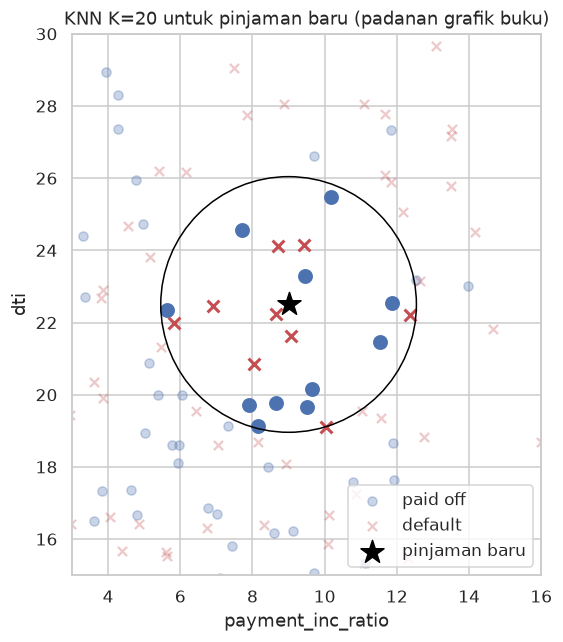

In [2]:
knn_predictors = ["payment_inc_ratio", "dti"]
newloan = loan200.loc[0:0, knn_predictors]
X200 = loan200.loc[1:, knn_predictors]
y200 = loan200.loc[1:, "outcome"]
knn20 = KNeighborsClassifier(n_neighbors=20).fit(X200, y200)
print("Prediksi:", knn20.predict(newloan)[0], "| probabilitas", dict(zip(knn20.classes_, knn20.predict_proba(newloan)[0])))
dist, idx = knn20.kneighbors(newloan)
neighbors = loan200.loc[1:].iloc[idx[0]]
display(neighbors.outcome.value_counts().rename("jumlah di 20 tetangga").to_frame())

all_dist = np.sort(np.sqrt(((X200 - newloan.to_numpy()) ** 2).sum(axis=1)))
print(f"Jarak tetangga ke-20 = {all_dist[19]:.4f}; ke-21 = {all_dist[20]:.4f} → seri di batas: {np.isclose(all_dist[19], all_dist[20])}")
display(pd.DataFrame([{"K": k, "P(default)": KNeighborsClassifier(n_neighbors=k).fit(X200, y200)
                       .predict_proba(newloan)[0, 0]} for k in [5, 10, 15, 20, 25, 30, 40]]).set_index("K").T.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
for cls, marker, color in [("paid off", "o", "C0"), ("default", "x", "C3")]:
    part = loan200[loan200.outcome == cls]
    ax.scatter(part.payment_inc_ratio, part.dti, marker=marker, color=color, alpha=.3, label=cls)
    near = neighbors[neighbors.outcome == cls]
    ax.scatter(near.payment_inc_ratio, near.dti, marker=marker, color=color, s=60, lw=2)
ax.scatter(*newloan.to_numpy()[0], marker="*", s=250, color="black", label="pinjaman baru")
ax.add_patch(Circle(newloan.to_numpy()[0], dist[0].max(), fill=False, edgecolor="black"))
ax.set(xlim=(3, 16), ylim=(15, 30), xlabel="payment_inc_ratio", ylabel="dti", aspect="equal",
       title="KNN K=20 untuk pinjaman baru (padanan grafik buku)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Dari 20 tetangga, 11 paid off dan 9 default, sehingga scikit-learn memprediksi **paid off** dengan P(default)=0,45, sama dengan output Python resmi. Tidak ada jarak seri di batas tetangga ke-20 (3,541 vs 3,588), jadi hasil ini tidak bergantung pada aturan pemecah seri. Namun kasus ini dekat batas keputusan: P(default) berayun dari 0,40 sampai 0,80 ketika K diubah antara 5 dan 40, dan label berganti beberapa kali. Satu prediksi KNN dengan probabilitas mendekati 0,5 tidak boleh ditafsirkan sebagai keputusan yang kuat.

<a id="c6-03"></a>
## Distance Metrics

*Acuan: cetak 241; PDF 259. Jenis: Teori + perbandingan tambahan.*

Kemiripan diukur dengan jarak antara vektor $x=(x_1,\dots,x_p)$ dan $u=(u_1,\dots,u_p)$:

- **Euclidean:** $\sqrt{\sum_j (x_j-u_j)^2}$ — jarak garis lurus; paling umum.
- **Manhattan:** $\sum_j |x_j-u_j|$ — jarak menyusuri blok kota; cocok bila perpindahan per sumbu lebih bermakna.
- **Mahalanobis:** $\sqrt{(x-u)^T\Sigma^{-1}(x-u)}$ — memperhitungkan korelasi dan skala antarvariabel melalui matriks kovarians $\Sigma$. Kelebihannya tidak terpengaruh variabel yang saling berkorelasi tinggi, tetapi lebih mahal dihitung dan rumit.

**Tambahan:** sel berikut memprediksi pinjaman baru `loan200` memakai ketiga metrik dan membandingkan himpunan tetangganya.

In [3]:
cov_inv = np.linalg.inv(np.cov(X200.to_numpy(), rowvar=False))
metric_models = {"euclidean": KNeighborsClassifier(n_neighbors=20),
                 "manhattan": KNeighborsClassifier(n_neighbors=20, metric="manhattan"),
                 "mahalanobis": KNeighborsClassifier(n_neighbors=20, metric="mahalanobis",
                                                     metric_params={"VI": cov_inv}, algorithm="brute")}
neighbor_sets, rows = {}, []
for name, model in metric_models.items():
    model.fit(X200, y200)
    neighbor_sets[name] = set(model.kneighbors(newloan)[1][0])
    rows.append({"metrik": name, "P(default)": model.predict_proba(newloan)[0, 0], "prediksi": model.predict(newloan)[0],
                 "tetangga sama dengan Euclidean": len(neighbor_sets[name] & neighbor_sets["euclidean"])})
display(pd.DataFrame(rows).set_index("metrik").round(3))
print("Simpangan baku prediktor:", X200.std().round(3).to_dict())

,P(default),prediksi,tetangga sama dengan Euclidean
metrik,,,
euclidean,0.45,paid off,20
manhattan,0.40,paid off,19
mahalanobis,0.45,paid off,15


Simpangan baku prediktor: {'payment_inc_ratio': 4.167, 'dti': 6.92}


**Interpretasi dan catatan belajar.** Manhattan berbagi 19 dari 20 tetangga dengan Euclidean, tetapi satu tetangga yang berganti cukup untuk menurunkan P(default) dari 0,45 ke 0,40. Mahalanobis menimbang ulang sumbu dengan simpangan baku dan korelasinya sehingga hanya 15 tetangga yang sama; komposisi kelasnya kebetulan tetap 9:11. Ketiga metrik memprediksi paid off. Pada data dua dimensi ini simpangan baku kedua prediktor masih sebanding (≈4,2 dan ≈6,9); masalah skala baru terasa besar di bagian standardisasi.

<a id="c6-04"></a>
## One Hot Encoder

*Acuan: cetak 242; PDF 260. Jenis: Teori + demonstrasi tambahan.*

Jarak hanya dapat dihitung pada angka, sehingga prediktor kategori diubah menjadi variabel biner **one-hot**: satu kolom 0/1 untuk setiap level. Berbeda dari regresi linear/logistik (yang membuang satu level sebagai referensi untuk menghindari multikolinearitas dengan intercept), KNN dan tree biasanya memakai **semua** level karena tidak ada intercept yang membuat kolom redundan menjadi masalah. Pada scikit-learn padanannya `pd.get_dummies` atau `OneHotEncoder`.

In [4]:
display(loan_data.home_ownership.value_counts().rename("jumlah").to_frame().T)
one_hot = pd.get_dummies(loan_data.home_ownership, dtype=int)
display(one_hot.assign(home_ownership=loan_data.home_ownership).head(6))
assert (one_hot.sum(axis=1) == 1).all()

home_ownership,MORTGAGE,RENT,OWN,OTHER
jumlah,20876,20665,3722,79


,MORTGAGE,OTHER,OWN,RENT,home_ownership
0,0,0,0,1,RENT
1,0,0,1,0,OWN
2,0,0,0,1,RENT
3,0,0,0,1,RENT
4,0,0,0,1,RENT
5,0,0,0,1,RENT


**Interpretasi dan catatan belajar.** Empat level (`MORTGAGE`, `OTHER`, `OWN`, `RENT`) menjadi empat kolom, dan setiap baris memiliki tepat satu nilai 1. Level langka `OTHER` (79 record) tetap mendapat kolom sendiri. Jarak Euclidean antara dua kategori berbeda selalu $\sqrt2$, tanpa urutan antar-level. Jika variabel numerik tidak distandardisasi, kontribusi dummy (0/1) ini bisa tenggelam oleh variabel bernilai ribuan.

<a id="c6-05"></a>
## Standardization (Normalization, z-Scores)

*Acuan: cetak 243; PDF 261. Jenis: Reproduksi Python buku.*

Standardisasi (z-score) mengubah variabel ke skala bersama: $z=(x-\bar x)/s$. Setelah itu, satu unit berarti satu simpangan baku. Tanpa standardisasi, variabel dengan angka besar mendominasi jarak. Istilah *normalization* di sini berarti penskalaan, bukan membuat data berdistribusi normal.

Contoh buku memakai empat prediktor `loan_data`: `payment_inc_ratio`, `dti`, `revol_bal`, dan `revol_util`, lalu membandingkan 5 tetangga terdekat untuk pinjaman indeks 0 sebelum dan sesudah standardisasi. Scaler dipelajari dari data latih (baris selain pinjaman baru), lalu diterapkan pada pinjaman baru.

In [5]:
std_predictors = ["payment_inc_ratio", "dti", "revol_bal", "revol_util"]
newloan4 = loan_data.loc[0:0, std_predictors]
X4 = loan_data.loc[1:, std_predictors]
y4 = loan_data.loc[1:, "outcome"]
print("Pinjaman baru:"); display(newloan4)
print("Simpangan baku data latih:", X4.std().round(2).to_dict())

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X4, y4)
print("5 tetangga TANPA standardisasi:"); display(X4.iloc[knn_raw.kneighbors(newloan4)[1][0]])
scaler = StandardScaler().fit(X4)
knn_std = KNeighborsClassifier(n_neighbors=5).fit(scaler.transform(X4), y4)
nbrs_std = knn_std.kneighbors(scaler.transform(newloan4))[1][0]
print("5 tetangga DENGAN standardisasi:"); display(X4.iloc[nbrs_std])
assert X4.iloc[nbrs_std].index[0] == 2080

Pinjaman baru:


,payment_inc_ratio,dti,revol_bal,revol_util
0,2.3932,1.0,1687,9.4


Simpangan baku data latih: {'payment_inc_ratio': 4.26, 'dti': 7.59, 'revol_bal': 20082.67, 'revol_util': 25.43}
5 tetangga TANPA standardisasi:


,payment_inc_ratio,dti,revol_bal,revol_util
35536,1.47212,1.46,1686,10.0
33651,3.38178,6.37,1688,8.4
25863,2.36303,1.39,1691,3.5
42953,1.28160,7.14,1684,3.9
43599,4.12244,8.98,1684,7.2


5 tetangga DENGAN standardisasi:


,payment_inc_ratio,dti,revol_bal,revol_util
2080,2.61091,1.03,1218,9.7
1438,2.34343,0.51,278,9.9
30215,2.71200,1.34,1075,8.5
28542,2.39760,0.74,2917,7.4
44737,2.34309,1.37,488,7.2


**Interpretasi dan catatan belajar.** Tanpa standardisasi, kelima tetangga memiliki `revol_bal` hampir persis 1.687 USD, tetapi `dti` dan `payment_inc_ratio` bisa jauh berbeda: simpangan baku `revol_bal` ribuan kali lebih besar sehingga mendominasi jarak. Setelah standardisasi, tetangga mirip di keempat variabel sekaligus, dan hasilnya sama dengan output buku (indeks 2080, 1438, 30215, 28542, 44737).

<a id="c6-06"></a>
## Choosing K

*Acuan: cetak 246; PDF 264. Jenis: Teori + cross-validation tambahan.*

K kecil membuat prediksi mengikuti noise lokal (**overfitting**); K besar meratakan terlalu banyak sehingga struktur lokal hilang (**oversmoothing**). Buku menyebut K umumnya berada di rentang 1–20, sering dipilih ganjil untuk klasifikasi biner agar tidak seri, dan nilai terbaik dicari dengan data validasi. Keseimbangan ini contoh **bias–variance tradeoff**.

**Tambahan:** 5-fold stratified CV pada `loan_data` (empat prediktor bagian sebelumnya) memakai pipeline `StandardScaler → KNN`, sehingga scaler hanya belajar dari fold latih.

,accuracy train,accuracy CV,AUC CV
K,,,
1,1.0000,0.5345,0.5345
5,0.7098,0.5506,0.5695
11,0.6576,0.5658,0.5905
21,0.6320,0.5744,0.6049
51,0.6127,0.5868,0.6213
101,0.6037,0.5894,0.6290
201,0.6017,0.5946,0.6336


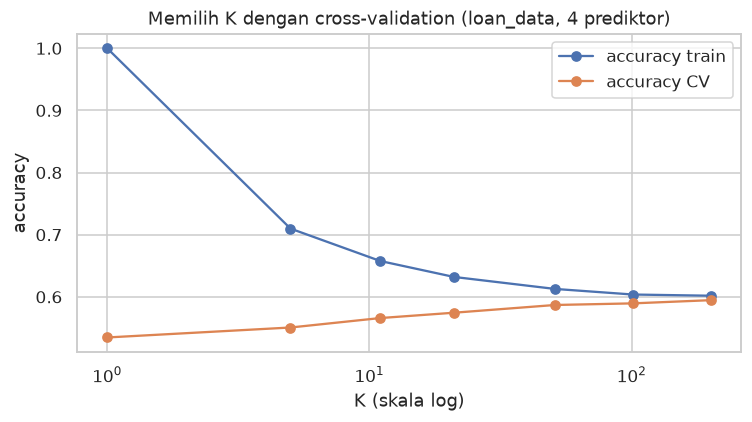

In [6]:
X_k, y_k = loan_data[std_predictors], loan_data["y"]
rows = []
for k in [1, 5, 11, 21, 51, 101, 201]:
    res = cross_validate(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X_k, y_k, cv=cv5,
                         scoring=["accuracy", "roc_auc"], return_train_score=True)
    rows.append({"K": k, "accuracy train": res["train_accuracy"].mean(), "accuracy CV": res["test_accuracy"].mean(),
                 "AUC CV": res["test_roc_auc"].mean()})
choose_k = pd.DataFrame(rows).set_index("K")
display(choose_k.round(4))
ax = choose_k[["accuracy train", "accuracy CV"]].plot(marker="o", logx=True)
ax.set(xlabel="K (skala log)", ylabel="accuracy", title="Memilih K dengan cross-validation (loan_data, 4 prediktor)")
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** K=1 hampir sempurna pada data latih tetapi paling buruk di CV: tanda overfitting yang klasik. Accuracy dan AUC CV terus naik perlahan ketika K membesar, sampai ≈0,595 dan ≈0,634 pada K=201, sementara accuracy latih turun mendekati CV. Dengan empat prediktor kredit ini kemampuan prediksi memang lemah; pada data sebesar ini K terbaik bisa jauh di atas rentang 1–20 yang disebut buku sebagai titik awal.

<a id="c6-07"></a>
## KNN as a Feature Engine

*Acuan: cetak 247; PDF 265. Jenis: Reproduksi Python dengan perbaikan kolom + analisis leakage tambahan.*

KNN dapat dipakai untuk membuat **fitur baru** bagi model lain: prediksi KNN dari beberapa variabel dimasukkan sebagai satu prediktor. Buku memakai 20 tetangga dari enam variabel kredit (`dti`, `revol_bal`, `revol_util`, `open_acc`, `delinq_2yrs_zero`, `pub_rec_zero`) untuk membentuk `borrower_score`, yaitu proporsi tetangga yang **paid off** (skor tinggi = mirip peminjam yang lunas). Fitur ini kemudian dipakai di Bab 5.

**Catatan adaptasi:** kode Python buku mengambil kolom `predict_proba(X)[:, 0]`. Karena kelas scikit-learn diurutkan alfabet (`default`, `paid off`), kolom 0 adalah peluang **default**, kebalikan dari definisi skor. Notebook memilih kolom kelas `paid off` secara eksplisit dan memverifikasinya terhadap kolom `borrower_score` dataset.

**Tambahan leakage:** prediksi in-sample memasukkan record itu sendiri sebagai tetangga (jarak 0), sehingga outcome record ikut menyumbang 1/20 ke skornya. Versi out-of-fold (5-fold) dibandingkan untuk melihat seberapa optimistis skor in-sample.

classes_: ['default' 'paid off']


Korelasi dengan borrower_score dataset = 0.9996; nilai identik = 99.83%


,borrower_score hasil KNN
count,45342.0000
mean,0.4989
std,0.1287
min,0.0500
25%,0.4000
50%,0.5000
75%,0.6000
max,1.0000


Record yang tetangga terdekatnya adalah dirinya sendiri: 99.8%


,AUC skor sendiri,AUC holdout regresi logistik Bab 5
versi skor,,
in-sample (cara buku),0.6573,0.6894
out-of-fold 5-fold,0.5451,0.6185


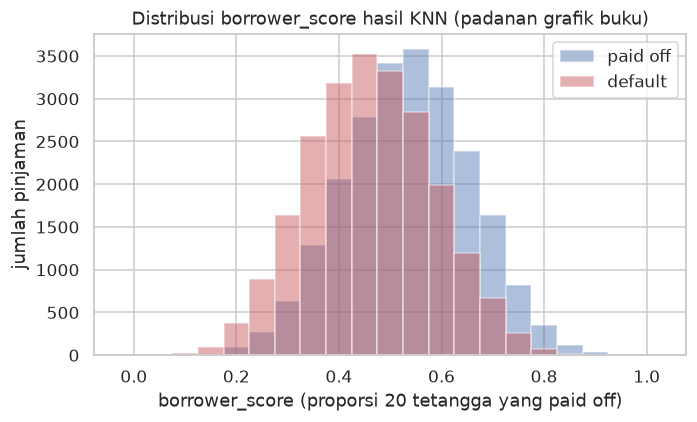

In [7]:
feature_predictors = ["dti", "revol_bal", "revol_util", "open_acc", "delinq_2yrs_zero", "pub_rec_zero"]
X_f = loan_data[feature_predictors]
knn_feature = KNeighborsClassifier(n_neighbors=20).fit(X_f, loan_data["outcome"])
print("classes_:", knn_feature.classes_)
paid_col = list(knn_feature.classes_).index("paid off")
score_insample = knn_feature.predict_proba(X_f)[:, paid_col]
print(f"Korelasi dengan borrower_score dataset = {np.corrcoef(score_insample, loan_data.borrower_score)[0, 1]:.4f}; "
      f"nilai identik = {100 * np.isclose(score_insample, loan_data.borrower_score).mean():.2f}%")
display(pd.Series(score_insample).describe().round(4).to_frame("borrower_score hasil KNN"))

score_oof = cross_val_predict(KNeighborsClassifier(n_neighbors=20), X_f, loan_data["y"], cv=cv5, method="predict_proba")[:, 0]
self_first = knn_feature.kneighbors(X_f, n_neighbors=1)[1][:, 0] == np.arange(len(X_f))
print(f"Record yang tetangga terdekatnya adalah dirinya sendiri: {100 * self_first.mean():.1f}%")

base_cols = ["payment_inc_ratio", "purpose_", "home_", "emp_len_"]
X_base = pd.get_dummies(loan_data[base_cols], drop_first=True, dtype=int)
tr, te = train_test_split(loan_data.index, test_size=0.3, random_state=SEED, stratify=loan_data["y"])
rows = []
for label, score in [("in-sample (cara buku)", score_insample), ("out-of-fold 5-fold", score_oof)]:
    Xs = X_base.assign(borrower_score=score)
    model = LogisticRegression(C=np.inf, solver="newton-cholesky", max_iter=500).fit(Xs.loc[tr], loan_data.y.loc[tr])
    rows.append({"versi skor": label, "AUC skor sendiri": roc_auc_score(loan_data.y, 1 - score),
                 "AUC holdout regresi logistik Bab 5": roc_auc_score(loan_data.y.loc[te], model.predict_proba(Xs.loc[te])[:, 1])})
display(pd.DataFrame(rows).set_index("versi skor").round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
bins = np.arange(-0.025, 1.05, 0.05)
for cls, color in [("paid off", "C0"), ("default", "C3")]:
    ax.hist(score_insample[loan_data.outcome == cls], bins=bins, alpha=.45, color=color, label=cls)
ax.set(xlabel="borrower_score (proporsi 20 tetangga yang paid off)", ylabel="jumlah pinjaman",
       title="Distribusi borrower_score hasil KNN (padanan grafik buku)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Skor hasil KNN identik dengan kolom `borrower_score` dataset pada hampir semua record, sehingga asal fitur Bab 5 terbukti. Pada 99,8% record, tetangga terdekat adalah record itu sendiri. AUC skor in-sample ≈0,657, sedangkan versi out-of-fold hanya ≈0,545: sebagian besar "kekuatan" skor berasal dari outcome record itu sendiri. Ketika skor out-of-fold dipakai, AUC holdout regresi logistik Bab 5 turun dari ≈0,689 menjadi ≈0,619. Jadi angka Bab 5 yang memakai `borrower_score` optimistis. Pelajaran umumnya: fitur yang dibangun dari target harus dihitung di dalam fold latih, sama seperti prinsip ZipGroup di Bab 4.

<a id="c6-08"></a>
## Tree Models

*Acuan: cetak 249; PDF 267. Jenis: Teori.*

Tree model (CART: classification and regression trees; juga disebut decision tree) adalah himpunan aturan "jika–maka" yang mudah dipahami dan diterapkan. Model ini dapat menemukan pola nonlinear dan interaksi tanpa spesifikasi manual, serta tidak memerlukan standardisasi. Tree juga menjadi dasar metode ensemble yang kuat (random forest dan boosting).

Istilah kunci: **recursive partitioning** (membagi data berulang kali agar hasil tiap partisi makin homogen), **split value** (nilai prediktor yang memisahkan dua partisi), **node** (aturan pemisah; di tree tampil sebagai cabang), **leaf** (akhir rangkaian aturan yang memberi prediksi), **loss** (jumlah salah klasifikasi pada suatu tahap), **impurity** (heterogenitas kelas dalam partisi), dan **pruning** (memangkas tree yang sudah tumbuh penuh untuk mengurangi overfitting).

<a id="c6-09"></a>
## A Simple Example

*Acuan: cetak 250; PDF 268. Jenis: Reproduksi Python; plot_tree menggantikan dmba.*

Contoh buku memfit tree pada `loan3000` dengan prediktor `borrower_score` dan `payment_inc_ratio`, kriteria entropy, dan `min_impurity_decrease=0.003` sebagai aturan berhenti. Kode buku menggambar tree dengan `dmba.plotDecisionTree` (membutuhkan Graphviz); notebook ini memakai `sklearn.tree.plot_tree` dan `export_text` agar tidak menambah dependency. Setiap node menampilkan jumlah record dan proporsi kelas.

Kelas: ['default' 'paid off'] | jumlah leaf: 6 | kedalaman: 3


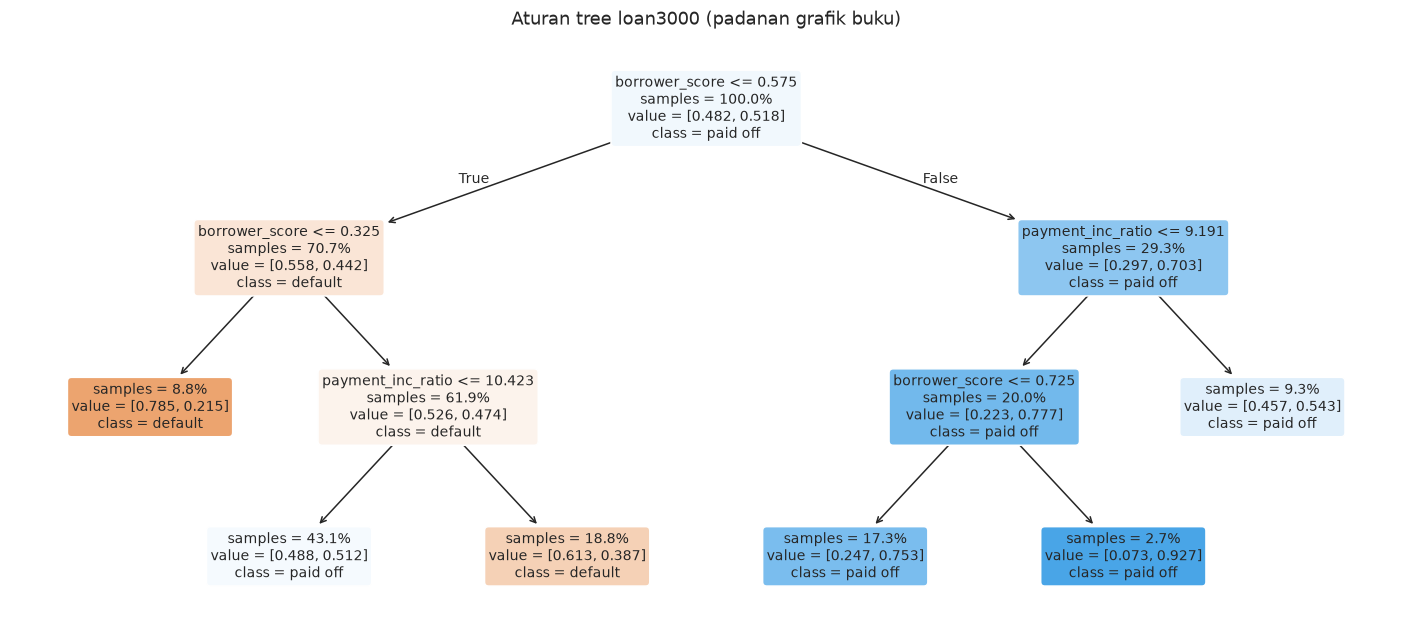

|--- borrower_score <= 0.575
|   |--- borrower_score <= 0.325
|   |   |--- weights: [208.000, 57.000] class: default
|   |--- borrower_score >  0.325
|   |   |--- payment_inc_ratio <= 10.423
|   |   |   |--- weights: [631.000, 663.000] class: paid off
|   |   |--- payment_inc_ratio >  10.423
|   |   |   |--- weights: [345.000, 218.000] class: default
|--- borrower_score >  0.575
|   |--- payment_inc_ratio <= 9.191
|   |   |--- borrower_score <= 0.725
|   |   |   |--- weights: [128.000, 390.000] class: paid off
|   |   |--- borrower_score >  0.725
|   |   |   |--- weights: [6.000, 76.000] class: paid off
|   |--- payment_inc_ratio >  9.191
|   |   |--- weights: [127.000, 151.000] class: paid off



In [8]:
X2 = loan3000[["borrower_score", "payment_inc_ratio"]]
y2 = loan3000["outcome"]
loan_tree = DecisionTreeClassifier(random_state=SEED, criterion="entropy", min_impurity_decrease=0.003).fit(X2, y2)
print("Kelas:", loan_tree.classes_, "| jumlah leaf:", loan_tree.get_n_leaves(), "| kedalaman:", loan_tree.get_depth())
fig, ax = plt.subplots(figsize=(13, 6))
plot_tree(loan_tree, feature_names=list(X2.columns), class_names=list(loan_tree.classes_), proportion=True,
          filled=True, impurity=False, rounded=True, fontsize=9, ax=ax)
ax.set_title("Aturan tree loan3000 (padanan grafik buku)"); plt.tight_layout(); plt.show()
print(export_text(loan_tree, feature_names=list(X2.columns), show_weights=True, decimals=3))

**Interpretasi dan catatan belajar.** Split pertama memakai `borrower_score` ≈0,575. Skor di bawah 0,325 langsung diprediksi default; skor 0,325–0,575 diprediksi default hanya bila `payment_inc_ratio` > 10,42. Bobot pada `export_text` adalah jumlah record [default, paid off] di tiap leaf; dari situ terlihat beberapa leaf hanya sedikit lebih condong ke satu kelas. Cabang kanan yang berakhir dengan prediksi sama (paid off) tetap dipertahankan karena split tersebut menurunkan entropy, walaupun tidak mengubah label.

<a id="c6-10"></a>
## The Recursive Partitioning Algorithm

*Acuan: cetak 252; PDF 270. Jenis: Reproduksi grafik buku dengan batas dibaca dari tree.*

Algoritme recursive partitioning untuk respons Y dan prediktor $X_1,\dots,X_p$:

1. Untuk setiap prediktor $X_j$ dan setiap kandidat split value $s_j$: bagi record menjadi $X_j<s_j$ dan $X_j\ge s_j$, lalu ukur homogenitas kelas di masing-masing partisi.
2. Pilih pasangan $(X_j,s_j)$ yang menghasilkan homogenitas terbaik.
3. Ulangi langkah 1–2 secara rekursif pada setiap partisi, sampai tidak ada split yang cukup memperbaiki homogenitas.

Hasilnya adalah partisi persegi panjang sejajar sumbu. **Adaptasi:** kode Python buku menuliskan koordinat batas secara manual; notebook membaca batas langsung dari struktur `tree_`, lalu memeriksanya terhadap angka buku (0,575; 0,325; 10,42; 9,19; 0,725). Tree R pada buku memakai `rpart` (Gini, parameter `cp`) sehingga split-nya sedikit berbeda dari versi Python ini.

Split value dari tree: [np.float64(0.325), np.float64(0.575), np.float64(0.725), np.float64(9.191), np.float64(10.423)]


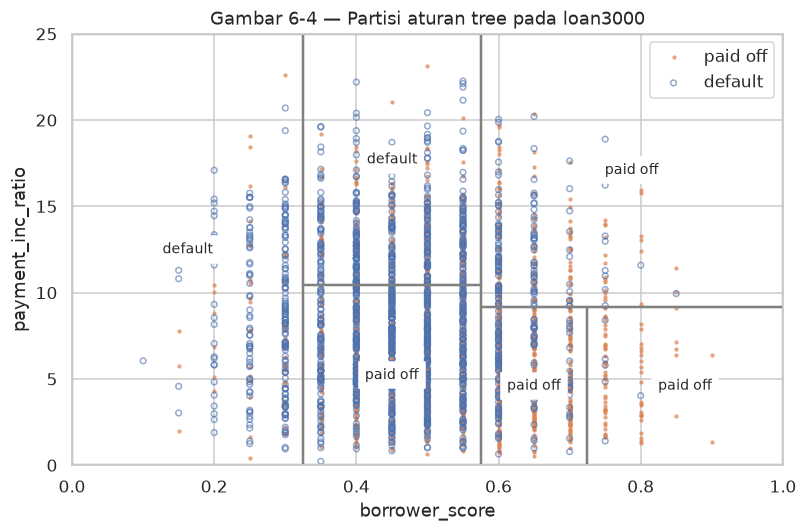

In [9]:
t = loan_tree.tree_
regions = []
def collect(node, bounds):
    if t.children_left[node] == -1:
        regions.append((bounds.copy(), loan_tree.classes_[np.argmax(t.value[node][0])]))
        return
    f, thr = t.feature[node], t.threshold[node]
    left, right = {k: list(v) for k, v in bounds.items()}, {k: list(v) for k, v in bounds.items()}
    left[f][1], right[f][0] = thr, thr
    collect(t.children_left[node], left); collect(t.children_right[node], right)
collect(0, {0: [0.0, 1.0], 1: [0.0, 25.0]})
thresholds = sorted(np.round(t.threshold[t.feature >= 0], 3))
print("Split value dari tree:", thresholds)
assert np.allclose(thresholds, sorted([0.575, 0.325, 10.423, 9.191, 0.725]), atol=1e-3)

fig, ax = plt.subplots(figsize=(7.5, 5))
for cls, marker, color in [("paid off", ".", "C1"), ("default", "o", "C0")]:
    part = loan3000[loan3000.outcome == cls]
    ax.scatter(part.borrower_score, part.payment_inc_ratio, marker=marker, facecolors="none" if marker == "o" else color,
               edgecolors=color, s=14, alpha=.6, label=cls)
for (b, label) in regions:
    (x0, x1), (y0, y1) = b[0], b[1]
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="grey", lw=1.5))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2, label, ha="center", va="center", fontsize=9, bbox={"facecolor": "white"})
ax.set(xlim=(0, 1), ylim=(0, 25), xlabel="borrower_score", ylabel="payment_inc_ratio",
       title="Gambar 6-4 — Partisi aturan tree pada loan3000")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Enam persegi panjang adalah enam leaf. Wilayah default berada di kiri (skor rendah) dan di tengah-atas (skor menengah dengan rasio pembayaran tinggi). Setiap batas sejajar sumbu; untuk meniru batas miring LDA/logistik, tree membutuhkan banyak split bertangga.

<a id="c6-11"></a>
## Measuring Homogeneity or Impurity

*Acuan: cetak 254; PDF 272. Jenis: Reproduksi grafik buku + verifikasi information gain tambahan.*

Untuk partisi A dengan proporsi kelas $p_k$:

- **Accuracy/misclassification:** proporsi record yang salah diklasifikasikan bila partisi diberi kelas mayoritas. Buku menjelaskan ukuran ini kurang sensitif untuk memilih split.
- **Gini impurity:** $I(A)=\sum_k p_k(1-p_k)$; untuk dua kelas $=2p(1-p)$.
- **Entropy:** $I(A)=-\sum_k p_k\log_2 p_k$.

Semua bernilai nol untuk partisi murni dan maksimum saat kelas seimbang. Split dipilih untuk memaksimalkan penurunan impurity berbobot ukuran partisi (*information gain* bila memakai entropy). Grafik mengikuti normalisasi kode buku: accuracy dan Gini diskalakan agar maksimum 1. **Tambahan:** information gain split akar dihitung manual dan dibandingkan dengan `tree_.impurity`.

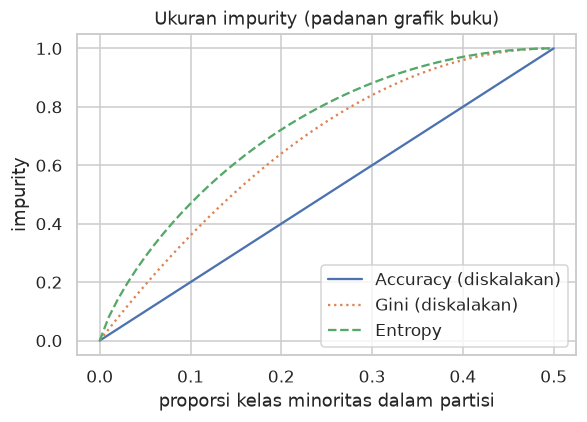

,manual,sklearn tree_
entropy akar,0.99903,0.99903
entropy kiri,0.99028,0.99028
entropy kanan,0.87792,0.87792
information gain,0.04163,0.04163


In [10]:
def entropy(p):
    p = np.asarray(p, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.nan_to_num(-p * np.log2(p) - (1 - p) * np.log2(1 - p))
x = np.linspace(0, 0.5, 51)
impure = pd.DataFrame({"x": x, "Accuracy (diskalakan)": 2 * x, "Gini (diskalakan)": (x * (1 - x)) / 0.25, "Entropy": entropy(x)})
ax = impure.plot(x="x", style=["-", ":", "--"], figsize=(5.5, 4))
ax.set(xlabel="proporsi kelas minoritas dalam partisi", ylabel="impurity", title="Ukuran impurity (padanan grafik buku)")
plt.tight_layout(); plt.show()

root_left = loan3000.borrower_score <= t.threshold[0]
def H(series): return float(entropy((series == "default").mean()))
n, nl = len(loan3000), root_left.sum()
gain = H(y2) - (nl / n) * H(y2[root_left]) - ((n - nl) / n) * H(y2[~root_left])
display(pd.DataFrame({"manual": [H(y2), H(y2[root_left]), H(y2[~root_left]), gain],
                      "sklearn tree_": [t.impurity[0], t.impurity[t.children_left[0]], t.impurity[t.children_right[0]],
                                        t.impurity[0] - (nl * t.impurity[t.children_left[0]] + (n - nl) * t.impurity[t.children_right[0]]) / n]},
                     index=["entropy akar", "entropy kiri", "entropy kanan", "information gain"]).round(5))

**Interpretasi dan catatan belajar.** Entropy akar ≈0,999 bit karena kelas hampir seimbang (48% default). Split pertama hanya menurunkan entropy sekitar 0,042 bit; split terbaik pun tidak membuat partisi mendekati murni, konsisten dengan tumpang tindih kelas di Bab 5. Perhitungan manual sama dengan nilai internal scikit-learn.

<a id="c6-12"></a>
## Stopping the Tree from Growing

*Acuan: cetak 256; PDF 274. Jenis: Teori + cost-complexity pruning tambahan.*

Tree yang dibiarkan tumbuh terus akan memecah data sampai setiap leaf murni, termasuk memecah noise: akurasi latih tinggi, prediksi data baru buruk. Cara mengendalikannya:

- **Aturan berhenti:** jangan memecah partisi yang terlalu kecil (`min_samples_split`/minsplit), jangan membuat leaf terlalu kecil (`min_samples_leaf`/minbucket), atau hentikan bila penurunan impurity kurang dari ambang (`min_impurity_decrease`, mirip `cp` pada R).
- **Pruning:** tumbuhkan tree besar lalu pangkas cabang yang tidak memperbaiki error pada data validasi. Parameter complexity (cp di R, `ccp_alpha` di scikit-learn) menghukum jumlah leaf; nilainya dipilih dengan cross-validation.

**Tambahan:** jalur cost-complexity pruning pada `loan3000`, dengan `ccp_alpha` dipilih memakai 5-fold CV.

,ccp_alpha,leaf,accuracy train,accuracy CV
0,0.0000,1245,0.9987,0.5717
1,0.0004,1219,0.9947,0.5717
38,0.0022,12,0.6253,0.6123
39,0.0163,2,0.6003,0.6003


Tree penuh: 1245 leaf, accuracy latih 0.999. Tree buku (6 leaf): accuracy CV 0.6070.


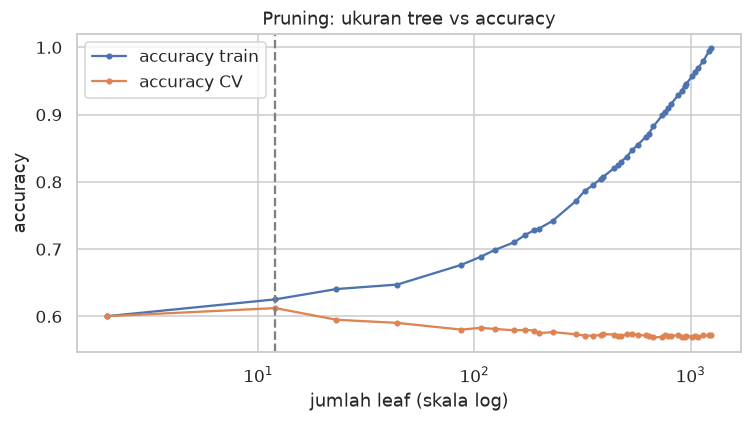

In [11]:
full_tree = DecisionTreeClassifier(random_state=SEED, criterion="entropy").fit(X2, y2)
path = full_tree.cost_complexity_pruning_path(X2, y2)
alphas = np.unique(np.r_[0, path.ccp_alphas[:-1]])
alphas = alphas[np.linspace(0, len(alphas) - 1, 40).astype(int)]
rows = []
for a in alphas:
    model = DecisionTreeClassifier(random_state=SEED, criterion="entropy", ccp_alpha=a)
    rows.append({"ccp_alpha": a, "leaf": model.fit(X2, y2).get_n_leaves(),
                 "accuracy train": model.score(X2, y2), "accuracy CV": cross_val_score(model, X2, y2, cv=cv5).mean()})
pruning = pd.DataFrame(rows)
best = pruning.loc[pruning["accuracy CV"].idxmax()]
display(pd.concat([pruning.head(2), pruning.loc[[pruning["accuracy CV"].idxmax()]], pruning.tail(2)]).drop_duplicates().round(4))
book_cv = cross_val_score(loan_tree, X2, y2, cv=cv5).mean()
print(f"Tree penuh: {full_tree.get_n_leaves()} leaf, accuracy latih {full_tree.score(X2, y2):.3f}. "
      f"Tree buku (6 leaf): accuracy CV {book_cv:.4f}.")
ax = pruning.plot(x="leaf", y=["accuracy train", "accuracy CV"], marker=".", logx=True)
ax.axvline(best["leaf"], color="grey", ls="--")
ax.set(xlabel="jumlah leaf (skala log)", ylabel="accuracy", title="Pruning: ukuran tree vs accuracy")
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Tree penuh memiliki 1.245 leaf dengan accuracy latih ≈0,999 tetapi accuracy CV hanya ≈0,572. Accuracy CV terbaik (≈0,612) tercapai pada tree 12 leaf; tree 6-leaf dari buku (≈0,607) berada di kisaran yang sama. Kurva latih yang terus naik sementara CV turun adalah gambaran langsung overfitting.

<a id="c6-13"></a>
## Predicting a Continuous Value

*Acuan: cetak 257; PDF 275. Jenis: Teori + demonstrasi tambahan pada data rumah Bab 4.*

Untuk target numerik, tree memakai logika yang sama, tetapi impurity diukur dengan **kuadrat deviasi dari mean** di tiap partisi (setara MSE/variance), dan prediksi leaf adalah **rata-rata** target di leaf tersebut. Kinerja dinilai dengan RMSE seperti regresi.

**Tambahan:** regression tree kedalaman 2 memprediksi `AdjSalePrice` dari `SqFtTotLiving` dan `BldgGrade` (data rumah Bab 4), dengan verifikasi bahwa nilai leaf = mean target dan impurity = variance.

In [12]:
house = pd.read_csv(DATA / "house_sales.csv", sep="\t")
Xh, yh = house[["SqFtTotLiving", "BldgGrade"]], house["AdjSalePrice"]
reg_tree = DecisionTreeRegressor(max_depth=2, random_state=SEED).fit(Xh, yh)
print(export_text(reg_tree, feature_names=list(Xh.columns), decimals=0))
leaf_id = reg_tree.apply(Xh)
check = pd.DataFrame({"n": pd.Series(leaf_id).value_counts().sort_index(),
                      "mean target (USD)": yh.groupby(leaf_id).mean(),
                      "nilai leaf tree (USD)": [reg_tree.tree_.value[i][0][0] for i in sorted(set(leaf_id))]})
display(check.round(0))
assert np.allclose(check["mean target (USD)"], check["nilai leaf tree (USD)"])
assert np.isclose(reg_tree.tree_.impurity[0], yh.var(ddof=0))
print(f"RMSE latih tree kedalaman 2 = USD {np.sqrt(np.mean((yh - reg_tree.predict(Xh)) ** 2)):,.0f}; "
      f"simpangan baku harga = USD {yh.std(ddof=0):,.0f}")

|--- BldgGrade <= 10
|   |--- BldgGrade <= 8
|   |   |--- value: [456188]
|   |--- BldgGrade >  8
|   |   |--- value: [795074]
|--- BldgGrade >  10
|   |--- BldgGrade <= 12
|   |   |--- value: [1187530]
|   |--- BldgGrade >  12
|   |   |--- value: [2711575]



,n,mean target (USD),nilai leaf tree (USD)
2,18078,456188.0,456188.0
3,2825,795074.0,795074.0
5,1645,1187530.0,1187530.0
6,139,2711575.0,2711575.0


RMSE latih tree kedalaman 2 = USD 275,992; simpangan baku harga = USD 385,394


**Interpretasi dan catatan belajar.** Empat leaf memberi empat harga rata-rata, sehingga prediksi berbentuk tangga. Ketiga split memakai `BldgGrade` (≤10, lalu ≤8 dan ≤12): pada kedalaman 2, grade lebih menurunkan variance daripada luas hidup. Leaf grade >12 hanya berisi 139 rumah dengan rata-rata ≈USD2,7 juta. Impurity akar sama dengan variance harga; RMSE latih jauh di bawah simpangan baku tetapi masih besar, karena empat nilai rata-rata tidak bisa menangkap variasi harga yang halus.

<a id="c6-14"></a>
## How Trees Are Used

*Acuan: cetak 258; PDF 276. Jenis: Teori + demonstrasi ketidakstabilan tambahan.*

Kelebihan tree menurut buku: aturan dapat divisualisasikan dan dijelaskan kepada pengguna non-teknis, mampu menangkap hubungan nonlinear dan interaksi, dapat menangani prediktor kategori dan numerik, serta dapat dikonversi menjadi aturan bisnis. Tree juga dapat menangani missing value (misalnya surrogate split pada `rpart`). Kelemahannya: satu tree biasanya kurang akurat dan **tidak stabil**—perubahan kecil pada data dapat mengubah struktur tree. Ensemble (random forest dan boosting) jauh lebih akurat, tetapi aturan tunggal yang mudah dibaca hilang.

**Tambahan:** tree dengan pengaturan buku difit pada lima sampel bootstrap `loan3000` untuk melihat variasi strukturnya.

In [13]:
rng = np.random.default_rng(SEED)
rows = []
for b in range(5):
    idx = rng.integers(0, len(loan3000), len(loan3000))
    tb = DecisionTreeClassifier(random_state=SEED, criterion="entropy", min_impurity_decrease=0.003).fit(X2.iloc[idx], y2.iloc[idx])
    splits = [f"{X2.columns[f]} ≤ {thr:.3f}" for f, thr in zip(tb.tree_.feature, tb.tree_.threshold) if f >= 0]
    rows.append({"bootstrap": b + 1, "leaf": tb.get_n_leaves(), "split akar": splits[0], "semua split (urutan pre-order)": "; ".join(splits)})
display(pd.DataFrame(rows).set_index("bootstrap"))

,leaf,split akar,semua split (urutan pre-order)
bootstrap,,,
1,13,borrower_score ≤ 0.575,borrower_score ≤ 0.575; borrower_score ≤ 0.325...
2,7,borrower_score ≤ 0.625,borrower_score ≤ 0.625; borrower_score ≤ 0.325...
3,8,borrower_score ≤ 0.575,borrower_score ≤ 0.575; borrower_score ≤ 0.375...
4,8,borrower_score ≤ 0.575,borrower_score ≤ 0.575; borrower_score ≤ 0.375...
5,11,borrower_score ≤ 0.425,borrower_score ≤ 0.425; payment_inc_ratio ≤ 10...


**Interpretasi dan catatan belajar.** Split akar selalu memakai `borrower_score`, tetapi nilainya berpindah antara 0,425 dan 0,625, dan jumlah leaf berkisar 7–13. Ketidakstabilan inilah yang dimanfaatkan bagging: merata-ratakan banyak tree yang berbeda menurunkan variansi prediksi.

<a id="c6-15"></a>
## Bagging and the Random Forest

*Acuan: cetak 259; PDF 277. Jenis: Teori.*

Rata-rata banyak penebak independen sering lebih akurat daripada penebak tunggal terbaik ("wisdom of crowds"). Dalam statistik, gagasan ini menjadi **ensemble**: gabungkan prediksi banyak model. Versi paling sederhana adalah merata-ratakan beberapa model berbeda pada data yang sama. Buku menyebut ensemble tree sangat efektif dan sering menjadi bagian solusi pemenang kompetisi prediksi.

Istilah kunci: **ensemble**, **bagging** (bootstrap aggregating: model dibangun dari sampel bootstrap lalu digabung), **random forest** (bagging tree + pengambilan sampel prediktor pada setiap split), dan **variable importance** (ukuran kontribusi prediktor terhadap kinerja model).

<a id="c6-16"></a>
## Bagging

*Acuan: cetak 260; PDF 278. Jenis: Teori + perbandingan tambahan.*

Algoritme bagging untuk respons Y dan prediktor X dengan n record:

1. Tetapkan jumlah model M; mulai dari m=1.
2. Ambil sampel bootstrap (dengan pengembalian) sebanyak n record dari data latih.
3. Latih model $\hat f_m(X)$ pada sampel tersebut.
4. Tambah m dan ulangi langkah 2–3 sampai m=M.
5. Prediksi bagging: $\hat f=\frac1M\sum_m\hat f_m(X)$ (untuk klasifikasi: rata-rata probabilitas atau voting).

Karena setiap model melihat sampel berbeda, kesalahan acak sebagian saling menghapus. **Tambahan:** 5-fold CV tree tunggal vs bagging 200 tree penuh pada `loan3000`.

In [14]:
single_full = DecisionTreeClassifier(random_state=SEED)
bagged = BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=SEED, n_jobs=-1)
rows = []
for name, model in [("Tree tunggal tumbuh penuh", single_full), ("Tree buku (6 leaf)", loan_tree), ("Bagging 200 tree penuh", bagged)]:
    res = cross_validate(model, X2, y2, cv=cv5, scoring=["accuracy", "roc_auc"])
    rows.append({"model": name, "accuracy CV": res["test_accuracy"].mean(), "AUC CV": res["test_roc_auc"].mean(),
                 "sd accuracy antar-fold": res["test_accuracy"].std()})
display(pd.DataFrame(rows).set_index("model").round(4))

,accuracy CV,AUC CV,sd accuracy antar-fold
model,,,
Tree tunggal tumbuh penuh,0.5647,0.5641,0.0103
Tree buku (6 leaf),0.6070,0.6577,0.0076
Bagging 200 tree penuh,0.5773,0.6155,0.0152


**Interpretasi dan catatan belajar.** Bagging menaikkan AUC tree penuh dari ≈0,56 menjadi ≈0,62 karena rata-rata banyak tree overfit lebih stabil daripada satu tree overfit. Namun tree kecil buku (AUC ≈0,66) masih lebih baik: pada dua prediktor yang bising, merata-ratakan tree yang sangat overfit belum cukup, dan membatasi kompleksitas tree tetap penting (bandingkan forest max_depth=5 di bagian berikutnya).

<a id="c6-17"></a>
## Random Forest

*Acuan: cetak 261; PDF 279. Jenis: Reproduksi Python buku; OOB dihitung inkremental.*

Random forest menambahkan satu langkah pada bagging tree: di setiap split hanya **sebagian prediktor acak** yang dipertimbangkan (`mtry` di R, `max_features` di scikit-learn; default klasifikasi $\sqrt p$). Ini membuat tree lebih beragam sehingga rata-ratanya lebih efektif.

Setiap tree tidak melihat sekitar 1/3 record (≈$e^{-1}$=36,8%) yang tidak terambil bootstrap. Prediksi untuk record memakai tree yang tidak melihatnya menghasilkan **out-of-bag (OOB) error**, perkiraan error data baru tanpa holdout terpisah.

Contoh buku: 500 tree pada `loan3000`, lalu OOB accuracy untuk jumlah tree 20–505. **Adaptasi:** loop memakai `warm_start=True` untuk menambah tree secara bertahap (tree awal identik dengan fit baru berseed sama, tetapi jauh lebih cepat). Grafik prediksi memakai prediksi OOB, sama dengan `predict()` tanpa data baru pada `randomForest` R; prediksi in-sample random forest hampir selalu benar sehingga menyesatkan.

Random forest 500 tree: OOB accuracy = 0.5753; accuracy in-sample = 0.9987


,default,paid off
0,0.181319,0.818681
1,0.267045,0.732955
2,0.933333,0.066667
3,0.173077,0.826923
4,1.000000,0.000000


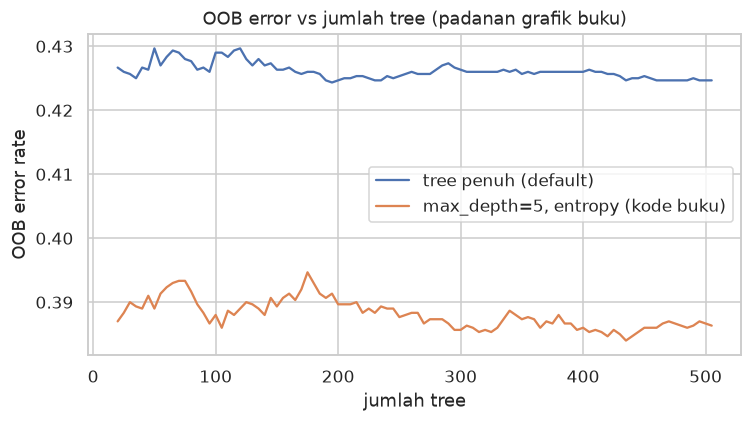

{'tree penuh (default)': np.float64(0.4247), 'max_depth=5, entropy (kode buku)': np.float64(0.3863)} | waktu 28.6 detik


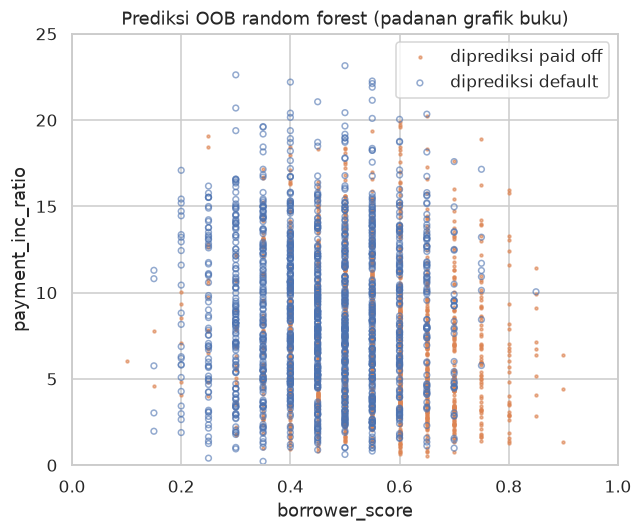

In [15]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=500, random_state=SEED, oob_score=True, n_jobs=-1).fit(X2, y2)
print(f"Random forest 500 tree: OOB accuracy = {rf.oob_score_:.4f}; accuracy in-sample = {rf.score(X2, y2):.4f}")
display(pd.DataFrame(rf.oob_decision_function_, columns=rf.classes_).head())

curves = {}
for label, params in [("tree penuh (default)", {}), ("max_depth=5, entropy (kode buku)", {"max_depth": 5, "criterion": "entropy"})]:
    model = RandomForestClassifier(warm_start=True, oob_score=True, random_state=SEED, n_jobs=-1, **params)
    scores = []
    for n_trees in range(20, 510, 5):
        model.set_params(n_estimators=n_trees).fit(X2, y2)
        scores.append(1 - model.oob_score_)
    curves[label] = pd.Series(scores, index=range(20, 510, 5))
ax = pd.DataFrame(curves).plot()
ax.set(xlabel="jumlah tree", ylabel="OOB error rate", title="OOB error vs jumlah tree (padanan grafik buku)")
plt.tight_layout(); plt.show()
print({k: round(v.iloc[-1], 4) for k, v in curves.items()}, f"| waktu {time.time() - t0:.1f} detik")

oob_pred = rf.classes_[rf.oob_decision_function_.argmax(axis=1)]
fig, ax = plt.subplots(figsize=(6, 5))
for cls, marker, color in [("paid off", ".", "C1"), ("default", "o", "C0")]:
    part = X2[oob_pred == cls]
    ax.scatter(part.borrower_score, part.payment_inc_ratio, marker=marker, s=14, alpha=.6,
               facecolors="none" if marker == "o" else color, edgecolors=color, label=f"diprediksi {cls}")
ax.set(xlim=(0, 1), ylim=(0, 25), xlabel="borrower_score", ylabel="payment_inc_ratio",
       title="Prediksi OOB random forest (padanan grafik buku)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Accuracy in-sample random forest mendekati 1, sedangkan OOB accuracy hanya sekitar 0,57–0,58: contoh nyata mengapa skor latih tidak boleh dipakai. Sejak 20 tree, OOB error sudah dekat nilai akhirnya dan hanya berfluktuasi kecil; menambah tree tidak menyebabkan overfit, hanya menambah waktu hitung. Forest berisi tree dangkal (max_depth=5) memiliki OOB error ≈0,386, lebih rendah daripada ≈0,425 untuk tree penuh pada data dua prediktor ini. Grafik prediksi OOB memperlihatkan batas yang tidak beraturan: random forest tetap mempelajari pola lokal yang sebagian adalah noise.

<a id="c6-18"></a>
## Variable Importance

*Acuan: cetak 265; PDF 283. Jenis: Reproduksi Python buku; permutation importance memakai holdout.*

Random forest dapat menilai kepentingan prediktor dengan dua cara yang dibahas buku:

1. **Penurunan accuracy (permutation):** acak nilai satu prediktor pada data yang tidak dipakai melatih, lalu ukur turunnya accuracy. Mengukur kontribusi prediktor terhadap kinerja prediksi.
2. **Penurunan rata-rata impurity (Gini decrease):** total penurunan Gini dari semua split yang memakai prediktor tersebut. Dihitung dari data latih, cepat, tetapi cenderung berpihak pada prediktor kontinu atau berlevel banyak.

Contoh buku memakai 17 prediktor `loan_data`. Pada R, accuracy decrease dihitung otomatis dengan OOB; kode Python buku mengulangi 3 split acak. **Adaptasi:** notebook memakai `sklearn.inspection.permutation_importance` pada holdout stratified 30% (5 ulangan acak), dilaporkan sebagai penurunan relatif $(acc-acc_{acak})/acc$ seperti kode buku. Catatan: `borrower_score` dibuat dari outcome data yang sama, sehingga kepentingannya kemungkinan terlalu tinggi, dan beberapa prediktor saling redundan (`purpose`/`purpose_`, `emp_length`/`emp_len_`).

Matriks fitur: (45342, 33)


Accuracy holdout random forest = 0.6629; waktu 210.1 detik


,feature,Accuracy decrease,Gini decrease,Entropy decrease
11,borrower_score,0.0733,0.0875,0.0793
9,grade,0.0358,0.0969,0.0910
12,term_60 months,0.0298,0.0207,0.0169
1,annual_inc,0.0167,0.0933,0.0942
3,payment_inc_ratio,0.0125,0.1058,0.1068
2,dti,0.0044,0.0991,0.1017
8,open_acc,0.0039,0.0673,0.0702
4,revol_bal,0.0026,0.0942,0.0977
29,purpose__small_business,0.0020,0.0034,0.0029
21,purpose_small_business,0.0018,0.0033,0.0030


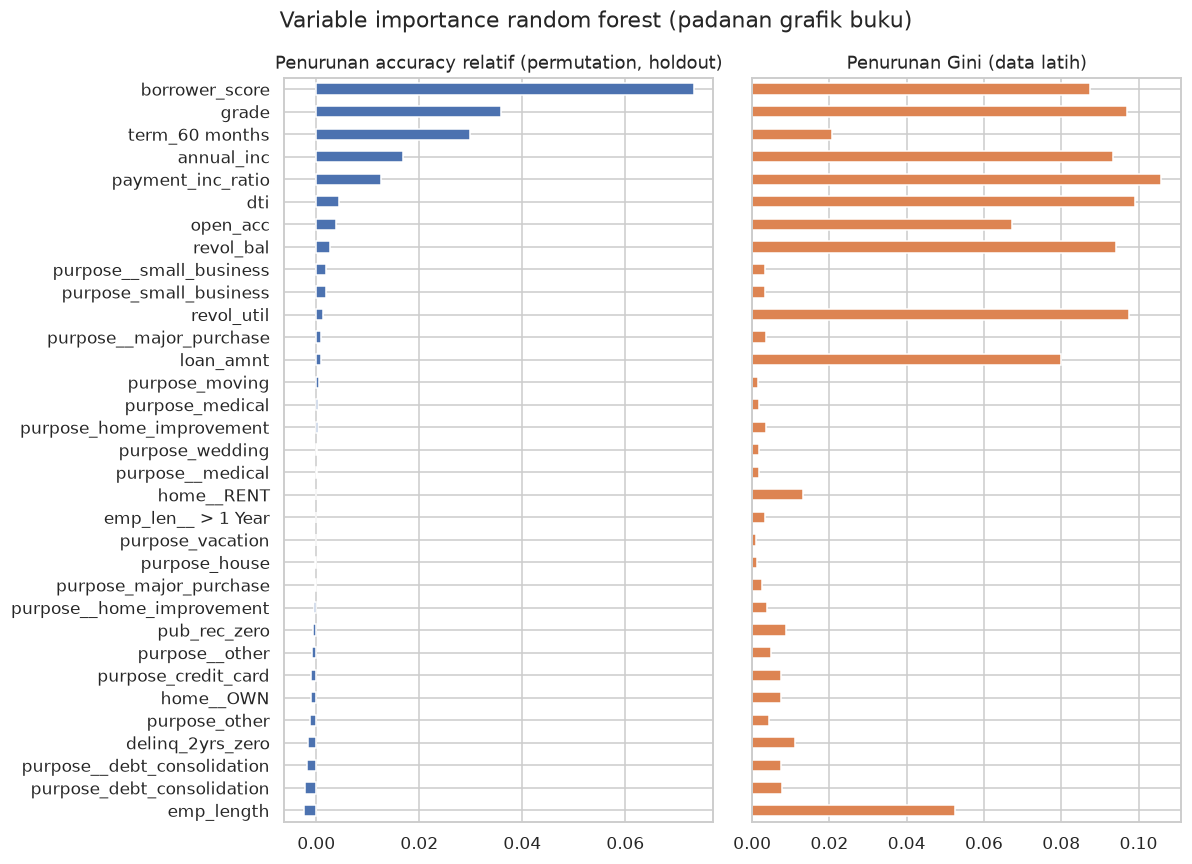

In [16]:
t0 = time.time()
vi_predictors = ["loan_amnt", "term", "annual_inc", "dti", "payment_inc_ratio", "revol_bal", "revol_util", "purpose",
                 "delinq_2yrs_zero", "pub_rec_zero", "open_acc", "grade", "emp_length", "purpose_", "home_", "emp_len_",
                 "borrower_score"]
X_all = pd.get_dummies(loan_data[vi_predictors], drop_first=True, dtype=int)
y_all = loan_data["outcome"]
print("Matriks fitur:", X_all.shape)
# Forest 500 tree penuh pada 45 ribu record cukup besar di memori: simpan importance lalu lepaskan modelnya.
rf_all = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1).fit(X_all, y_all)
gini_importance = rf_all.feature_importances_
del rf_all
rf_all_entropy = RandomForestClassifier(n_estimators=500, random_state=SEED, criterion="entropy", n_jobs=-1).fit(X_all, y_all)
entropy_importance = rf_all_entropy.feature_importances_
del rf_all_entropy

tr_X, va_X, tr_y, va_y = train_test_split(X_all, y_all, test_size=0.3, random_state=SEED, stratify=y_all)
rf_vi = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1).fit(tr_X, tr_y)
base_acc = rf_vi.score(va_X, va_y)
perm = permutation_importance(rf_vi, va_X, va_y, scoring="accuracy", n_repeats=5, random_state=SEED)
del rf_vi
importance = pd.DataFrame({"feature": X_all.columns, "Accuracy decrease": perm.importances_mean / base_acc,
                           "Gini decrease": gini_importance,
                           "Entropy decrease": entropy_importance}).sort_values("Accuracy decrease")
print(f"Accuracy holdout random forest = {base_acc:.4f}; waktu {time.time() - t0:.1f} detik")
display(importance.sort_values("Accuracy decrease", ascending=False).head(10).round(4))

fig, axes = plt.subplots(ncols=2, figsize=(11, 8), sharey=True)
importance.plot.barh(x="feature", y="Accuracy decrease", legend=False, ax=axes[0])
importance.plot.barh(x="feature", y="Gini decrease", legend=False, ax=axes[1], color="C1")
axes[0].set(title="Penurunan accuracy relatif (permutation, holdout)", ylabel="")
axes[1].set(title="Penurunan Gini (data latih)")
fig.suptitle("Variable importance random forest (padanan grafik buku)")
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Permutation importance menempatkan `borrower_score` paling atas, diikuti `grade`, `term_60 months`, `annual_inc`, dan `payment_inc_ratio`, mirip urutan output Python resmi. Gini decrease memberi gambaran berbeda: variabel kontinu seperti `payment_inc_ratio`, `dti`, `revol_util`, dan `revol_bal` mendapat nilai setara atau lebih tinggi daripada `borrower_score`, padahal permutation importance `dti`/`revol_bal` kecil, dan `emp_length` bahkan bernilai negatif. Gini cenderung memihak variabel dengan banyak kandidat split. Dummy `purpose` rinci dan `purpose_` hampir tidak berarti karena informasinya terbagi di dua versi. Kepentingan `borrower_score` perlu dibaca bersama hasil leakage di bagian KNN feature engine.

<a id="c6-19"></a>
## Hyperparameters

*Acuan: cetak 269; PDF 287. Jenis: Teori + pencarian kecil tambahan.*

Random forest relatif "black box" dan memiliki **hyperparameter**, yaitu pengaturan yang ditetapkan sebelum fit, bukan dipelajari dari data. Yang disorot buku:

- **nodesize/min_samples_leaf:** ukuran minimum leaf; default R untuk klasifikasi 1 dan regresi 5.
- **maxnodes/max_leaf_nodes:** jumlah maksimum leaf per tree; default tanpa batas.
- **mtry/max_features:** jumlah prediktor yang diacak per split.

Mengabaikan hyperparameter dapat menyebabkan overfitting, terutama untuk data bising. Nilai yang baik dicari dengan validasi. **Tambahan:** OOB accuracy untuk grid kecil `min_samples_leaf` × `max_features` (200 tree per kombinasi agar cepat).

In [17]:
t0 = time.time()
rows = []
for leaf in [1, 10, 50]:
    for mf in ["sqrt", 0.5]:
        model = RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, max_features=mf, oob_score=True,
                                       random_state=SEED, n_jobs=-1).fit(X_all, y_all)
        rows.append({"min_samples_leaf": leaf, "max_features": mf, "OOB accuracy": model.oob_score_})
hp_rf = pd.DataFrame(rows)
display(hp_rf.pivot(index="min_samples_leaf", columns="max_features", values="OOB accuracy").round(4))
print(f"waktu {time.time() - t0:.1f} detik")

max_features,0.5,sqrt
min_samples_leaf,,
1,0.6520,0.6599
10,0.6626,0.6662
50,0.6634,0.6670


waktu 65.1 detik


**Interpretasi dan catatan belajar.** Leaf yang lebih besar (tree lebih sederhana) memberi OOB accuracy lebih baik daripada leaf berukuran 1 pada data pinjaman yang bising ini. OOB accuracy naik dari ≈0,652–0,660 (leaf 1) menjadi ≈0,663–0,667 (leaf 50), dan `max_features="sqrt"` sedikit lebih baik daripada 0,5. Selisih sekitar 1 poin persen ini menunjukkan default bukan selalu pilihan terbaik. OOB dipakai sebagai skor validasi; pemilihan terbaik dari grid ini sebaiknya dikonfirmasi pada holdout terpisah sebelum dilaporkan sebagai kinerja akhir.

<a id="c6-20"></a>
## Boosting

*Acuan: cetak 270; PDF 288. Jenis: Teori.*

Boosting juga ensemble, tetapi model dibangun **berurutan**: setiap model baru memfokuskan diri pada record yang salah diprediksi model sebelumnya. Bagging dapat dipakai hampir tanpa penyetelan, sedangkan boosting lebih kuat namun membutuhkan perhatian pada hyperparameter.

Istilah kunci: **ensemble**, **boosting**, **AdaBoost** (versi awal yang memberi bobot ulang record berdasarkan residual), **gradient boosting** (bentuk umum yang memfit model baru pada arah penurunan fungsi loss/pseudo-residual), **stochastic gradient boosting** (gradient boosting dengan subsampling record dan prediktor di setiap iterasi), **regularization** (penalti pada kompleksitas model untuk mencegah overfitting), dan **hyperparameter**.

<a id="c6-21"></a>
## The Boosting Algorithm

*Acuan: cetak 271; PDF 289. Jenis: Teori + implementasi AdaBoost tambahan.*

Bentuk dasar AdaBoost untuk respons biner $y_i\in\{-1,+1\}$:

1. Tetapkan jumlah model M; mulai dari bobot $w_i=1/N$ untuk semua record.
2. Latih model $\hat f_m$ dengan bobot $w$ dan hitung error berbobot $e_m=\sum_i w_i\,I(y_i\neq\hat f_m(x_i))$.
3. Hitung bobot model $\alpha_m=\log\frac{1-e_m}{e_m}$ dan tambahkan ke ensemble: $\hat F_m=\hat F_{m-1}+\alpha_m\hat f_m$.
4. Perbarui bobot record $w_i\leftarrow w_i\exp(\alpha_m I(y_i\neq\hat f_m(x_i)))$ lalu normalisasi: record yang salah mendapat bobot lebih besar.
5. Ulangi sampai M model; prediksi = tanda $\hat F_M$.

Beberapa buku menulis $\alpha_m$ dengan faktor 1/2 dan pembaruan bobot memakai $\exp(-\alpha_m y_i\hat f_m)$; setelah normalisasi, bobot record dan keputusan tanda identik. Gradient boosting menggeneralisasi ide ini dengan memfit pseudo-residual. **Tambahan:** implementasi manual 100 stump (tree kedalaman 1) dibandingkan dengan `AdaBoostClassifier` (SAMME, setara rumus di atas untuk dua kelas).

Kesepakatan prediksi manual vs AdaBoostClassifier: 100.00%
5 bobot model pertama (alpha): [0.4069 0.4141 0.2667 0.2021 0.0508] | scikit-learn: [0.4069 0.4141 0.2667 0.2021 0.0508]


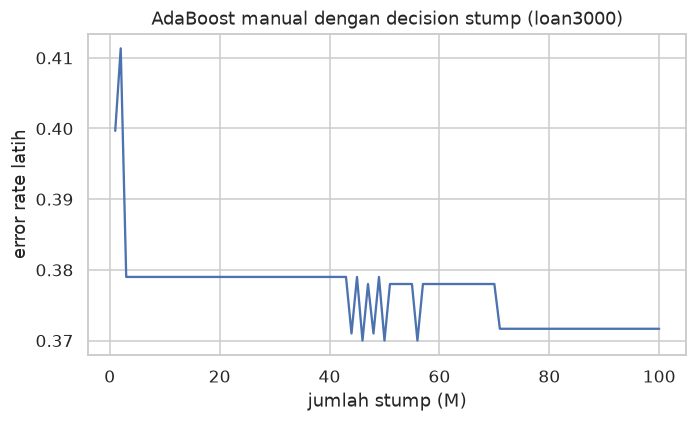

Accuracy CV 5-fold AdaBoost 100 stump: 0.6117


In [18]:
Xb, yb = X2.to_numpy(), np.where(loan3000["y"] == 1, 1, -1)
M = 100
w = np.full(len(yb), 1 / len(yb))
F = np.zeros(len(yb)); stumps, alphas_ada, errors = [], [], []
for m in range(M):
    stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(Xb, yb, sample_weight=w)
    miss = stump.predict(Xb) != yb
    e = np.sum(w[miss]) / np.sum(w)
    alpha = np.log((1 - e) / e)
    w = w * np.exp(alpha * miss); w = w / w.sum()
    F += alpha * stump.predict(Xb)
    stumps.append(stump); alphas_ada.append(alpha); errors.append(np.mean(np.sign(F) != yb))
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=M, random_state=SEED).fit(Xb, yb)
agree = np.mean(np.sign(F) == ada.predict(Xb))
print(f"Kesepakatan prediksi manual vs AdaBoostClassifier: {100 * agree:.2f}%")
print("5 bobot model pertama (alpha):", np.round(alphas_ada[:5], 4), "| scikit-learn:", np.round(ada.estimator_weights_[:5], 4))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(1, M + 1), errors)
ax.set(xlabel="jumlah stump (M)", ylabel="error rate latih", title="AdaBoost manual dengan decision stump (loan3000)")
plt.tight_layout(); plt.show()
print("Accuracy CV 5-fold AdaBoost 100 stump:", round(cross_val_score(ada, Xb, yb, cv=cv5).mean(), 4))

**Interpretasi dan catatan belajar.** Implementasi manual menghasilkan bobot model dan prediksi yang sama dengan scikit-learn. Error latih turun tajam pada tiga stump pertama (≈0,40 → ≈0,38) lalu hampir datar di sekitar 0,37–0,38: dengan dua prediktor, kombinasi stump cepat jenuh. Kurva tidak turun monoton karena AdaBoost meminimalkan loss eksponensial berbobot, bukan error rate secara langsung. Accuracy CV ≈0,612 setara tree kecil buku. Penurunan error latih tidak otomatis berarti error data baru turun; boosting dengan model fleksibel dan iterasi banyak justru rawan overfitting, sehingga perlu regularisasi.

<a id="c6-22"></a>
## XGBoost

*Acuan: cetak 272; PDF 290. Jenis: Reproduksi Python buku dengan perbaikan kolom probabilitas.*

XGBoost adalah implementasi stochastic gradient boosting yang sangat populer dan efisien. Parameter penting: `subsample` (fraksi record per iterasi), `colsample_bytree` (fraksi prediktor), `learning_rate`/`eta` (faktor penyusut kontribusi tiap model), `n_estimators`/`nrounds`, dan `max_depth`. Contoh buku memakai `loan3000`, dua prediktor, `objective='binary:logistic'`, `subsample=0.63`, dengan target 1=default.

**Catatan adaptasi:** kode Python buku menyimpan `predict_proba(X)[:, 0]` sebagai `prob_default`, padahal kolom 0 adalah peluang **paid off** (kelas 0). Output resminya memperlihatkan record berprediksi default dengan `prob_default` 0,32. Notebook memakai kolom 1. `random_state=1` ditambahkan agar subsampling dapat diulang.

{'learning_rate': None, 'max_depth': None, 'n_estimators': None, 'reg_lambda': None, 'subsample': 0.63} (None = default XGBoost: 100 tree, max_depth 6, eta 0,3, lambda 1)


,borrower_score,payment_inc_ratio,prediction,prob_default
0,0.40,5.11135,paid off,0.251189
1,0.40,5.43165,default,0.634665
2,0.70,9.23003,default,0.587140
3,0.40,2.33482,paid off,0.338984
4,0.45,12.10320,default,0.912164


Accuracy in-sample = 0.7573; accuracy CV 5-fold = 0.5837


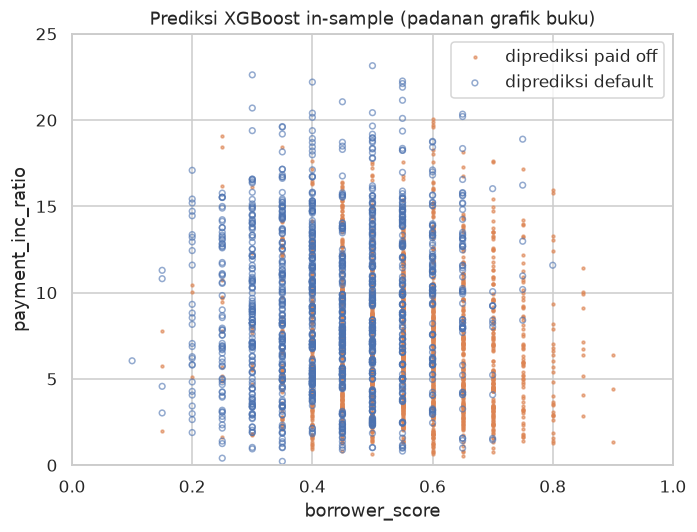

In [19]:
y2_num = loan3000["y"]
xgb = XGBClassifier(objective="binary:logistic", subsample=0.63, eval_metric="error", random_state=SEED)
xgb.fit(X2, y2_num)
print({k: v for k, v in xgb.get_params().items() if k in ["n_estimators", "max_depth", "learning_rate", "subsample", "reg_lambda"]},
      "(None = default XGBoost: 100 tree, max_depth 6, eta 0,3, lambda 1)")
xgb_df = X2.copy()
xgb_df["prediction"] = np.where(xgb.predict(X2) == 1, "default", "paid off")
xgb_df["prob_default"] = xgb.predict_proba(X2)[:, 1]
display(xgb_df.head())
assert ((xgb_df.prob_default > 0.5) == (xgb_df.prediction == "default")).all()
print(f"Accuracy in-sample = {accuracy_score(y2_num, xgb.predict(X2)):.4f}; "
      f"accuracy CV 5-fold = {cross_val_score(xgb, X2, y2_num, cv=cv5).mean():.4f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
for cls, marker, color in [("paid off", ".", "C1"), ("default", "o", "C0")]:
    part = xgb_df[xgb_df.prediction == cls]
    ax.scatter(part.borrower_score, part.payment_inc_ratio, marker=marker, s=14, alpha=.6,
               facecolors="none" if marker == "o" else color, edgecolors=color, label=f"diprediksi {cls}")
ax.set(xlim=(0, 1), ylim=(0, 25), xlabel="borrower_score", ylabel="payment_inc_ratio",
       title="Prediksi XGBoost in-sample (padanan grafik buku)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Kolom `prob_default` kini konsisten dengan label: setiap record berprediksi default memiliki probabilitas di atas 0,5. Pola prediksi mirip random forest—wilayah default di kiri dan kiri-atas—tetapi dengan batas tidak beraturan. Selisih accuracy in-sample dan CV menunjukkan pengaturan default XGBoost (100 tree kedalaman 6) sudah mulai menghafal noise pada data dua prediktor ini.

<a id="c6-23"></a>
## Regularization: Avoiding Overfitting

*Acuan: cetak 274; PDF 292. Jenis: Reproduksi Python buku dengan iteration_range terkoreksi.*

Penerapan XGBoost yang ceroboh mudah overfit: model mengejar noise data latih. Pengendaliannya antara lain menurunkan `eta`, memakai subsampling, membatasi kedalaman, dan **regularisasi**, yaitu menambahkan penalti kompleksitas pada fungsi loss:

- `reg_lambda` (L2, mirip **ridge regression**): penalti jumlah kuadrat bobot leaf.
- `reg_alpha` (L1, mirip **lasso**): penalti jumlah nilai mutlak; dapat membuat bobot menjadi nol.

Ridge dan lasso pada regresi linear meminimalkan RSS ditambah $\lambda\sum\beta_j^2$ atau $\alpha\sum|\beta_j|$. Contoh buku membandingkan dua model pada 17 prediktor `loan_data` dengan 10.000 record validasi: **default** (`reg_lambda=0`, `eta=0.3`, `subsample=1`) dan **penalty** (`reg_lambda=1000`, `eta=0.1`, `subsample=0.63`), masing-masing 250 tree kedalaman 6.

**Catatan adaptasi:** kode buku memakai `iteration_range=[1, n+1]`, yang melewati tree pertama. Rentang yang benar untuk n tree pertama adalah `(0, n)`. Split memakai `random_state=1`.

,default,penalty
error latih,0.109,0.3115
error validasi,0.359,0.3294


,default train,penalty train,default test,penalty test
iterations,,,,
1,0.3421,0.3566,0.3486,0.3625
5,0.3223,0.3370,0.3337,0.3415
50,0.2561,0.3269,0.3396,0.3289
100,0.2058,0.3218,0.3483,0.3284
250,0.1090,0.3115,0.3590,0.3294


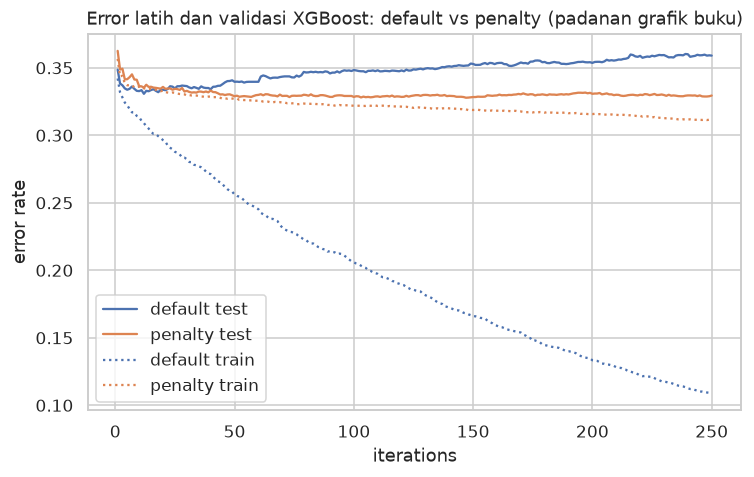

waktu 33.3 detik


In [20]:
t0 = time.time()
X_reg = X_all
y_reg = loan_data["y"]
train_X, valid_X, train_y, valid_y = train_test_split(X_reg, y_reg, test_size=10000, random_state=SEED)
xgb_default = XGBClassifier(objective="binary:logistic", n_estimators=250, max_depth=6, reg_lambda=0, learning_rate=0.3,
                            subsample=1, eval_metric="error", random_state=SEED).fit(train_X, train_y)
xgb_penalty = XGBClassifier(objective="binary:logistic", n_estimators=250, max_depth=6, reg_lambda=1000, learning_rate=0.1,
                            subsample=0.63, eval_metric="error", random_state=SEED).fit(train_X, train_y)
err = lambda model, X, y, n=None: np.mean(np.abs(y - model.predict_proba(X, **({"iteration_range": (0, n)} if n else {}))[:, 1]) > 0.5)
display(pd.DataFrame({"default": [err(xgb_default, train_X, train_y), err(xgb_default, valid_X, valid_y)],
                      "penalty": [err(xgb_penalty, train_X, train_y), err(xgb_penalty, valid_X, valid_y)]},
                     index=["error latih", "error validasi"]).round(4))
results = pd.DataFrame([{"iterations": n,
                         "default train": err(xgb_default, train_X, train_y, n), "penalty train": err(xgb_penalty, train_X, train_y, n),
                         "default test": err(xgb_default, valid_X, valid_y, n), "penalty test": err(xgb_penalty, valid_X, valid_y, n)}
                        for n in range(1, 251)])
display(results.iloc[[0, 4, 49, 99, 249]].set_index("iterations").round(4))
ax = results.plot(x="iterations", y=["default test", "penalty test", "default train", "penalty train"],
                  style=["-", "-", ":", ":"], color=["C0", "C1", "C0", "C1"], figsize=(7, 4.5))
ax.set(ylabel="error rate", title="Error latih dan validasi XGBoost: default vs penalty (padanan grafik buku)")
plt.tight_layout(); plt.show()
print(f"waktu {time.time() - t0:.1f} detik")

**Interpretasi dan catatan belajar.** Model default menurunkan error latih sampai ≈0,109, tetapi error validasinya paling rendah di awal (≈0,334 sekitar iterasi ke-5) lalu naik menjadi ≈0,359: overfitting. Model penalty belajar lebih lambat; error latih dan validasinya berdekatan dan error validasi akhirnya (≈0,329) lebih rendah daripada model default. Pola ini sesuai buku: regularisasi menukar sedikit kecocokan data latih dengan generalisasi yang lebih baik. Angka berbeda tipis dari output resmi karena split acak, seed, dan versi XGBoost.

<a id="c6-24"></a>
## Hyperparameters and Cross-Validation

*Acuan: cetak 279; PDF 297. Jenis: Reproduksi Python buku.*

XGBoost memiliki banyak hyperparameter yang saling memengaruhi, sehingga pemilihannya perlu sistematis. Buku menyebut parameter yang paling penting: `eta`/`learning_rate` (0–1, penyusut kontribusi tiap tree), `nrounds`/`n_estimators`, `max_depth` (default 6; nilai kecil mencegah interaksi berlebihan), `subsample` dan `colsample_bytree`, serta penalti `lambda`/`reg_lambda` dan `alpha`/`reg_alpha`.

Contoh buku: grid `eta` ∈ {0,1; 0,5; 0,9} × `max_depth` ∈ {3, 6, 9}, 250 tree, 5-fold CV dengan fold diacak per record. Error rata-rata CV dipakai untuk memilih kombinasi terbaik. Kode mempertahankan cara buku membentuk fold (`np.random.choice` dengan pengembalian, sehingga ukuran fold sedikit berbeda), memakai generator berseed.

In [21]:
t0 = time.time()
rng = np.random.default_rng(SEED)
fold_idx = rng.choice(range(5), size=len(X_reg), replace=True)
print("Ukuran fold:", np.bincount(fold_idx))
rows = []
for eta in [0.1, 0.5, 0.9]:
    for max_depth in [3, 6, 9]:
        cv_error = []
        for k in range(5):
            test_mask = fold_idx == k
            model = XGBClassifier(objective="binary:logistic", n_estimators=250, max_depth=max_depth, learning_rate=eta,
                                  eval_metric="error", random_state=SEED)
            model.fit(X_reg.loc[~test_mask], y_reg[~test_mask])
            cv_error.append(np.mean(np.abs(y_reg[test_mask] - model.predict_proba(X_reg.loc[test_mask])[:, 1]) > 0.5))
        rows.append({"eta": eta, "max_depth": max_depth, "avg_error": np.mean(cv_error), "sd_error": np.std(cv_error)})
errors = pd.DataFrame(rows)
display((errors.pivot_table(index="eta", columns="max_depth", values="avg_error") * 100).round(2))
best = errors.loc[errors.avg_error.idxmin()]
print(f"Terbaik: eta={best.eta}, max_depth={int(best.max_depth)}, error CV={100 * best.avg_error:.2f}% "
      f"(sd antar-fold {100 * best.sd_error:.2f} poin) | waktu {time.time() - t0:.1f} detik")

Ukuran fold: [9225 9053 9103 8967 8994]


max_depth,3,6,9
eta,,,
0.1,32.69,33.35,34.71
0.5,34.05,36.92,37.19
0.9,35.22,38.55,38.10


Terbaik: eta=0.1, max_depth=3, error CV=32.69% (sd antar-fold 0.60 poin) | waktu 41.5 detik


**Interpretasi dan catatan belajar.** Kombinasi `eta` kecil dan tree dangkal memberi error CV terendah (sekitar 33%), sama dengan kesimpulan buku. Error naik ketika `eta` atau `max_depth` membesar karena model belajar terlalu agresif dan menangkap noise. Selisih terbesar antar-sel (≈6 poin persen) jauh melampaui simpangan baku antar-fold (≈0,6 poin), sehingga pola umum "eta kecil + tree dangkal lebih baik" meyakinkan; selisih antar-sel terbaik (<1 poin) masih setara noise CV. Karena grid dipilih memakai CV yang sama, error terbaik sedikit optimistis; holdout akhir atau nested CV tetap diperlukan untuk klaim kinerja.

<a id="c6-25"></a>
## Summary

*Acuan: cetak 282; PDF 300. Jenis: Teori.*

KNN memprediksi dari record yang mirip sehingga sangat bergantung pada standardisasi, metrik jarak, dan K; prediksinya juga dapat dijadikan fitur, asalkan dibuat tanpa melihat target data validasi. Decision tree menghasilkan aturan yang mudah dibaca dengan split yang memaksimalkan homogenitas, tetapi perlu dibatasi atau dipangkas. Bagging dan random forest merata-ratakan banyak tree untuk menurunkan variansi dan memberi OOB error serta variable importance. Boosting membangun model berurutan dan, bersama regularisasi serta CV, sering menjadi salah satu metode prediksi terkuat untuk data tabular.

**Latihan:** jelaskan mengapa `revol_bal` mendominasi KNN tanpa standardisasi; buktikan dengan angka mengapa skor in-sample KNN bocor; bandingkan Gini dan entropy untuk satu split; jelaskan mengapa OOB error tidak naik ketika jumlah tree ditambah; ubah `reg_lambda` atau `max_depth` XGBoost dan catat efeknya pada error validasi.

**Batas hasil:** sebagian besar evaluasi memakai data seimbang dan split acak, bukan validasi waktu; `borrower_score` masih mengandung leakage pada bagian variable importance dan XGBoost; hyperparameter dipilih dengan CV yang sama dengan pelaporan error. Model adalah latihan metode, bukan sistem persetujuan kredit.

**Bacaan lanjutan:** buku memberi referensi tambahan pada akhir subbab Tree Models; rujuk buku untuk daftar lengkap. Untuk pendalaman umum ensemble dan boosting, *An Introduction to Statistical Learning* (James dkk.) dan *The Elements of Statistical Learning* (Hastie, Tibshirani, Friedman) dapat dipakai sebagai pelengkap.

## Referensi dan atribusi

- Peter Bruce, Andrew Bruce, Peter Gedeck. *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi 2, O’Reilly, 2020. ISBN 978-1-492-07294-2, Bab 6.
- [Kode dan dataset resmi pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); sumber khusus: `python/code/Chapter 6 - Statistical Machine Learning.py` dan notebook pendamping. Copyright kode upstream © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck. Modifikasi untuk tugas: penjelasan Indonesia, `plot_tree` menggantikan `dmba`, perbaikan kolom probabilitas KNN/XGBoost dan `iteration_range`, OOB inkremental, `permutation_importance`, seed, pemeriksaan hasil, dan tambahan belajar yang ditandai. Lisensi GPL-3.0: lihat [LICENSE](LICENSE).
- Dokumentasi scikit-learn (KNN, tree, ensemble, permutation importance, cost-complexity pruning) dan XGBoost dipakai untuk menyesuaikan API.

**Refleksi mahasiswa:**